# Étape 3 — Analyse exploratoire des données

Dans ce notebook, nous explorons les données House Prices pour notre travail de fin de session du cours MAP6014, à l'automne 2026. Nous suivons les éléments de l'étape 3 des consignes : description des données, statistiques descriptives, valeurs manquantes, distributions, corrélations et visualisations pertinentes. **Chaque figure est suivie d'un commentaire** structuré en quatre temps : la question posée, ce que nous observons, notre interprétation et la conséquence pour la suite du projet.

Une corrélation ou une différence de prix entre deux groupes de maisons ne démontre pas une causalité. Les constats de ce notebook décrivent des associations dans les ventes d'Ames entre 2006 et 2010.

## 1. Lien avec la présentation du problème

Le contexte, les objectifs de prédiction, les fichiers, le dictionnaire des variables et les défis sont présentés dans [l'étape 2 — Présentation du problème](02_presentation_probleme.ipynb). Ce notebook vérifie ces défis à l'aide des données : valeurs manquantes, catégories rares, asymétrie des prix, valeurs atypiques et caractéristiques corrélées.

L'analyse porte surtout sur `train.csv`, seul fichier contenant `SalePrice`. Nous examinons aussi `test.csv` lorsque nous comparons les valeurs manquantes et les catégories, sans jamais utiliser ce fichier pour définir une règle de préparation.

## 2. Description des données

### Lecture des données

À l'étape 2, nous avons lu les fichiers sous forme de texte afin de vérifier les codes bruts. Pour l'analyse, nous avons besoin de valeurs numériques. Nous lisons donc les CSV avec `na_values=["NA"]` et `keep_default_na=False` : seul le code `NA` devient une valeur absente, tandis que `None` reste une catégorie, par exemple « aucun parement de maçonnerie » dans `MasVnrType`. Les colonnes numériques sont alors reconnues automatiquement par pandas.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
from IPython.display import display
from matplotlib import MatplotlibDeprecationWarning
from matplotlib.ticker import NullFormatter

# Repérer la racine depuis le dossier courant ou l'un de ses parents.
current = Path.cwd().resolve()
root = next(
    (path for path in (current, *current.parents) if (path / "pyproject.toml").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis le dépôt MAP6014.")

data_dir = root / "data"
# Seul le code « NA » devient une valeur absente : « None » reste une catégorie.
read_options = {"na_values": ["NA"], "keep_default_na": False}
train = pd.read_csv(data_dir / "train.csv", **read_options)
test = pd.read_csv(data_dir / "test.csv", **read_options)
description_text = (data_dir / "data_description.txt").read_text(encoding="utf-8")

assert train.shape == (1460, 81)
assert test.shape == (1459, 80)
assert train["SalePrice"].notna().all() and train["SalePrice"].gt(0).all()
assert train["MasVnrType"].eq("None").any()

# Avertissement interne à seaborn, sans effet sur les figures.
warnings.filterwarnings("ignore", message="vert: bool", category=MatplotlibDeprecationWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100


def format_dollars(value):
    """Afficher un montant en dollars avec une espace comme séparateur de milliers."""
    return f"{value:,.0f} $".replace(",", " ")

### Types de variables

Le type informatique d'une colonne ne suffit pas à décrire sa signification. Nous regroupons donc les 79 caractéristiques selon leur nature, en nous appuyant sur `data_description.txt`.

In [2]:
categorical_text = [
    column for column in train.columns
    if not pd.api.types.is_numeric_dtype(train[column])
]
variable_groups = {
    "Surfaces, longueurs et montants": [
        "LotFrontage", "LotArea", "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2",
        "BsmtUnfSF", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "LowQualFinSF",
        "GrLivArea", "GarageArea", "WoodDeckSF", "OpenPorchSF", "EnclosedPorch",
        "3SsnPorch", "ScreenPorch", "PoolArea", "MiscVal",
    ],
    "Comptes (pièces, salles de bain, voitures)": [
        "BsmtFullBath", "BsmtHalfBath", "FullBath", "HalfBath", "BedroomAbvGr",
        "KitchenAbvGr", "TotRmsAbvGrd", "Fireplaces", "GarageCars",
    ],
    "Années et mois": ["YearBuilt", "YearRemodAdd", "GarageYrBlt", "MoSold", "YrSold"],
    "Scores numériques de 1 à 10": ["OverallQual", "OverallCond"],
    "Code numérique nominal": ["MSSubClass"],
    "Catégories textuelles": categorical_text,
}
features = [column for group in variable_groups.values() for column in group]
assert len(features) == 79 and set(features) == set(train.columns) - {"Id", "SalePrice"}

numeric_features = [
    column
    for group, columns in variable_groups.items()
    if group not in {"Code numérique nominal", "Catégories textuelles"}
    for column in columns
]
categorical_features = categorical_text + ["MSSubClass"]

display(pd.DataFrame(
    [(group, len(columns), ", ".join(columns[:5]) + (", …" if len(columns) > 5 else ""))
     for group, columns in variable_groups.items()],
    columns=["Groupe", "Nombre", "Exemples"],
))

,Groupe,Nombre,Exemples
0,"Surfaces, longueurs et montants",19,"LotFrontage, LotArea, MasVnrArea, BsmtFinSF1, ..."
1,"Comptes (pièces, salles de bain, voitures)",9,"BsmtFullBath, BsmtHalfBath, FullBath, HalfBath..."
2,Années et mois,5,"YearBuilt, YearRemodAdd, GarageYrBlt, MoSold, ..."
3,Scores numériques de 1 à 10,2,"OverallQual, OverallCond"
4,Code numérique nominal,1,MSSubClass
5,Catégories textuelles,43,"MSZoning, Street, Alley, LotShape, LandContour, …"


Les données comprennent **35 caractéristiques numériques quantitatives** (surfaces, comptes, années et scores) et **44 caractéristiques catégorielles** : les 43 colonnes textuelles et `MSSubClass`. Cette dernière est enregistrée avec des nombres, mais ses codes (20, 60, 190…) désignent des types de logement : la valeur 60 n'est pas « trois fois » la valeur 20. Nous la traiterons donc comme une catégorie.

`OverallQual` et `OverallCond` sont des scores ordonnés de 1 à 10. Nous les conservons parmi les variables numériques, car leur ordre a un sens, tout en sachant que l'écart entre deux niveaux n'est pas forcément constant. Plusieurs variables textuelles sont aussi ordonnées, par exemple les échelles de qualité `Ex`, `Gd`, `TA`, `Fa` et `Po` de `ExterQual`, `KitchenQual` ou `BsmtQual`.

### Concordance avec le dictionnaire des variables

Nous comparons ensuite les codes présents dans les CSV avec ceux décrits dans `data_description.txt`.

In [3]:
# Extraire les codes documentés de chaque variable textuelle dans data_description.txt.
documented_codes, current_variable = {}, None
for line in description_text.splitlines():
    header = re.match(r"^(\w+):", line)
    if header:
        current_variable = header.group(1)
        documented_codes[current_variable] = set()
        continue
    code = re.match(r"^\s+(\S[^\t]*?)\s*\t", line)
    if current_variable and code:
        documented_codes[current_variable].add(code.group(1).strip())

code_gaps = []
for column in categorical_text:
    observed = set(train[column].dropna()) | set(test[column].dropna())
    undocumented = observed - documented_codes.get(column, set())
    if undocumented:
        code_gaps.append({
            "Variable": column,
            "Codes présents dans les CSV": ", ".join(sorted(undocumented)),
            "Codes du dictionnaire non observés": ", ".join(
                sorted(documented_codes[column] - observed)
            ),
        })
display(pd.DataFrame(code_gaps))

,Variable,Codes présents dans les CSV,Codes du dictionnaire non observés
0,MSZoning,C (all),"A, C, I, RP"
1,Neighborhood,NAmes,Names
2,BldgType,"2fmCon, Duplex, Twnhs","2FmCon, Duplx, TwnhsI"
3,Exterior2nd,"Brk Cmn, CmentBd, Wd Shng","BrkComm, CemntBd, PreCast, WdShing"


Quatre variables contiennent des codes écrits différemment dans les données et dans le dictionnaire. Par exemple, `BldgType` utilise `Duplex` et `Twnhs` dans les CSV, alors que le dictionnaire indique `Duplx` et `TwnhsI`. De même, `Exterior2nd` contient `Wd Shng`, `CmentBd` et `Brk Cmn`, alors que `Exterior1st` utilise les codes du dictionnaire (`WdShing`, `CemntBd`, `BrkComm`) pour les mêmes matériaux. Il s'agit de différences d'écriture, pas de nouvelles catégories.

**Conséquence :** si nous comparons ou combinons `Exterior1st` et `Exterior2nd` à l'étape 4, nous devrons d'abord harmoniser ces codes. Les autres écarts n'ont pas d'effet sur l'analyse, mais nous utiliserons les codes des CSV dans nos tableaux.

## 3. Statistiques descriptives

### Variable cible : `SalePrice`

In [5]:
price = train["SalePrice"]
price_summary = pd.DataFrame({
    "Statistique": [
        "Nombre de maisons", "Moyenne", "Écart type", "Minimum", "1er quartile",
        "Médiane", "3e quartile", "Maximum",
        "Coefficient d'asymétrie", "Coefficient d'aplatissement (excès)",
    ],
    "Valeur": [
        f"{price.count():,}".replace(",", " "),
        format_dollars(price.mean()), format_dollars(price.std()),
        format_dollars(price.min()), format_dollars(price.quantile(0.25)),
        format_dollars(price.median()), format_dollars(price.quantile(0.75)),
        format_dollars(price.max()), f"{price.skew():.2f}", f"{price.kurt():.2f}",
    ],
})
display(price_summary)

,Statistique,Valeur
0,Nombre de maisons,1 460
1,Moyenne,180 921 $
2,Écart type,79 443 $
3,Minimum,34 900 $
4,1er quartile,129 975 $
5,Médiane,163 000 $
6,3e quartile,214 000 $
7,Maximum,755 000 $
8,Coefficient d'asymétrie,1.88
9,Coefficient d'aplatissement (excès),6.54


Les **1 460 prix de vente** vont de **34 900 \$ à 755 000 \$**. La moyenne (180 921 \$) est supérieure à la médiane (163 000 \$) : quelques maisons très chères tirent la moyenne vers le haut. Le coefficient d'asymétrie de 1,88 confirme une distribution étirée vers la droite, et l'aplatissement de 6,54 indique des valeurs extrêmes plus fréquentes que dans une loi normale. La section 5 examine cette distribution graphiquement.

### Principales caractéristiques numériques

In [6]:
key_numeric = [
    "LotArea", "GrLivArea", "TotalBsmtSF", "GarageArea",
    "TotRmsAbvGrd", "GarageCars", "OverallQual", "YearBuilt",
]
numeric_summary = (
    train[key_numeric].describe().T
    .rename(columns={
        "count": "Nombre", "mean": "Moyenne", "std": "Écart type", "min": "Minimum",
        "25%": "Q1", "50%": "Médiane", "75%": "Q3", "max": "Maximum",
    })
    .round(1)
)
display(numeric_summary)

,Nombre,Moyenne,Écart type,Minimum,Q1,Médiane,Q3,Maximum
LotArea,1460.0,10516.8,9981.3,1300.0,7553.5,9478.5,11601.5,215245.0
GrLivArea,1460.0,1515.5,525.5,334.0,1129.5,1464.0,1776.8,5642.0
TotalBsmtSF,1460.0,1057.4,438.7,0.0,795.8,991.5,1298.2,6110.0
GarageArea,1460.0,473.0,213.8,0.0,334.5,480.0,576.0,1418.0
TotRmsAbvGrd,1460.0,6.5,1.6,2.0,5.0,6.0,7.0,14.0
GarageCars,1460.0,1.8,0.7,0.0,1.0,2.0,2.0,4.0
OverallQual,1460.0,6.1,1.4,1.0,5.0,6.0,7.0,10.0
YearBuilt,1460.0,1971.3,30.2,1872.0,1954.0,1973.0,2000.0,2010.0


Les échelles sont très différentes : `LotArea` atteint 215 245 pi², alors que `GarageCars` varie de 0 à 4. Pour plusieurs surfaces, le maximum est très éloigné du troisième quartile, ce qui signale des maisons atypiques (par exemple `TotalBsmtSF` : Q3 de 1 298 pi² et maximum de 6 110 pi²). Le minimum de 0 pour `TotalBsmtSF` et `GarageArea` correspond à des maisons sans sous-sol ou sans garage, pas à des erreurs de saisie. Avec une médiane de construction en 1973, le parc immobilier est varié, de 1872 à 2010.

### Variables catégorielles

In [7]:
categorical_rows = []
for column in categorical_features:
    counts = train[column].value_counts(dropna=False)
    mode = counts.index[0]
    categorical_rows.append({
        "Variable": column,
        "Modalités observées": train[column].nunique(dropna=True),
        "Modalité la plus fréquente": "NA" if pd.isna(mode) else str(mode),
        "Part de cette modalité (%)": round(counts.iloc[0] / len(train) * 100, 1),
    })
categorical_summary = (
    pd.DataFrame(categorical_rows)
    .sort_values("Part de cette modalité (%)", ascending=False)
    .reset_index(drop=True)
)
quasi_constant = categorical_summary[categorical_summary["Part de cette modalité (%)"] >= 95]

print(f"{len(categorical_features)} variables catégorielles, dont "
      f"{len(quasi_constant)} dominées à 95 % ou plus par une seule modalité.")
display(quasi_constant)
display(
    categorical_summary.sort_values("Modalités observées", ascending=False).head(6)
)

44 variables catégorielles, dont 7 dominées à 95 % ou plus par une seule modalité.


,Variable,Modalités observées,Modalité la plus fréquente,Part de cette modalité (%)
0,Utilities,2,AllPub,99.9
1,Street,2,Pave,99.6
2,PoolQC,3,NA,99.5
3,Condition2,8,Norm,99.0
4,RoofMatl,8,CompShg,98.2
5,Heating,6,GasA,97.8
6,MiscFeature,4,NA,96.3


,Variable,Modalités observées,Modalité la plus fréquente,Part de cette modalité (%)
43,Neighborhood,25,NAmes,15.4
41,Exterior2nd,16,VinylSd,34.5
40,Exterior1st,15,VinylSd,35.3
39,MSSubClass,15,20,36.7
19,Condition1,9,Norm,86.3
18,SaleType,9,WD,86.8


Sept variables catégorielles sont dominées à **95 % ou plus** par une seule modalité. Par exemple, `Utilities` vaut `AllPub` pour 1 459 maisons sur 1 460 et `Street` vaut `Pave` pour 99,6 % d'entre elles. Ces variables apportent très peu d'information pour distinguer les maisons; une catégorie présente une ou deux fois ne permet pas d'estimer un effet fiable. À l'inverse, `Neighborhood` compte 25 quartiers et `Exterior1st`, `Exterior2nd` et `MSSubClass` en comptent 15 ou 16 : un encodage par indicateurs (*one-hot*) créerait donc de nombreuses colonnes.

**Conséquence :** à l'étape 4, nous devrons décider s'il faut retirer les variables quasi constantes ou regrouper les modalités rares.

## 4. Valeurs manquantes

Le dictionnaire précise que, pour 14 variables, le code `NA` signifie l'**absence d'un équipement** : pas de ruelle, de sous-sol, de foyer, de garage, de piscine, de clôture ou d'équipement particulier. Pour les autres variables, une valeur absente correspond à une **information inconnue**. Nous distinguons ces deux situations dans le tableau suivant.

In [8]:
# Variables pour lesquelles data_description.txt définit NA comme une absence.
absence_columns = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature",
]

missing = pd.DataFrame({
    "Train (n)": train[features].isna().sum(),
    "Test (n)": test[features].isna().sum(),
})
missing = missing[missing.sum(axis=1) > 0].copy()
missing["Train (%)"] = (missing["Train (n)"] / len(train) * 100).round(1)
missing["Test (%)"] = (missing["Test (n)"] / len(test) * 100).round(1)
missing["Nature selon le dictionnaire"] = np.where(
    missing.index.isin(absence_columns),
    "NA = équipement absent", "Information inconnue",
)
missing = missing.sort_values(["Train (n)", "Test (n)"], ascending=False)

print(f"Variables avec au moins une valeur absente : {missing['Train (n)'].gt(0).sum()} "
      f"dans train, {missing['Test (n)'].gt(0).sum()} dans test.")
display(missing)

Variables avec au moins une valeur absente : 19 dans train, 33 dans test.


,Train (n),Test (n),Train (%),Test (%),Nature selon le dictionnaire
PoolQC,1453,1456,99.5,99.8,NA = équipement absent
MiscFeature,1406,1408,96.3,96.5,NA = équipement absent
Alley,1369,1352,93.8,92.7,NA = équipement absent
Fence,1179,1169,80.8,80.1,NA = équipement absent
FireplaceQu,690,730,47.3,50.0,NA = équipement absent
LotFrontage,259,227,17.7,15.6,Information inconnue
GarageYrBlt,81,78,5.5,5.3,Information inconnue
GarageFinish,81,78,5.5,5.3,NA = équipement absent
GarageQual,81,78,5.5,5.3,NA = équipement absent
GarageCond,81,78,5.5,5.3,NA = équipement absent


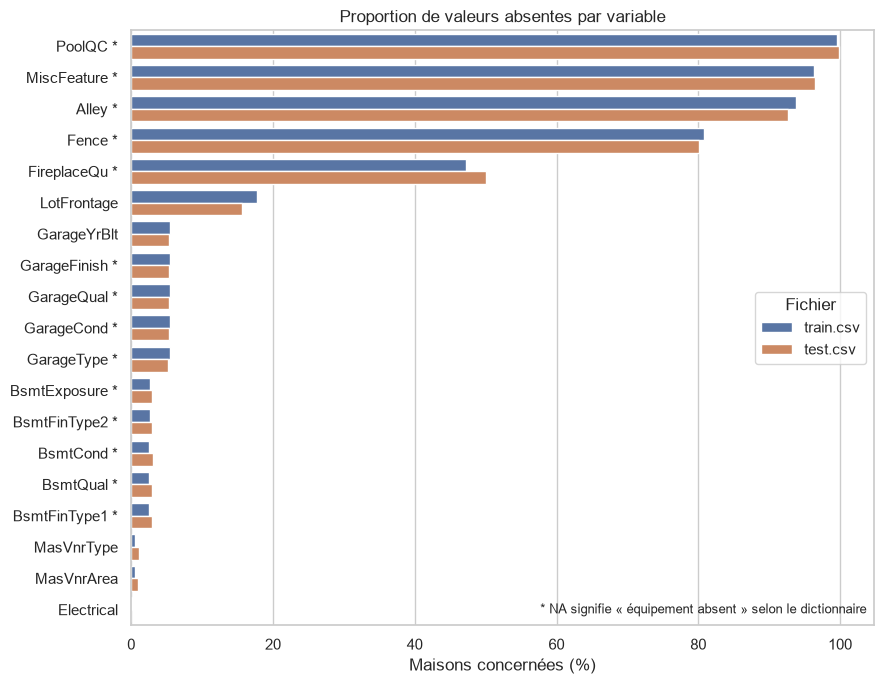

In [9]:
plot_missing = (
    missing[missing["Train (n)"] > 0][["Train (%)", "Test (%)"]]
    .rename(columns={"Train (%)": "train.csv", "Test (%)": "test.csv"})
)
plot_missing.index = [
    f"{name} *" if name in absence_columns else name for name in plot_missing.index
]
plot_missing = (
    plot_missing.reset_index(names="Variable")
    .melt(id_vars="Variable", var_name="Fichier", value_name="Pourcentage")
)

fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=plot_missing, y="Variable", x="Pourcentage", hue="Fichier", ax=ax)
ax.set_title("Proportion de valeurs absentes par variable")
ax.set_xlabel("Maisons concernées (%)")
ax.set_ylabel("")
ax.text(0.99, 0.02, "* NA signifie « équipement absent » selon le dictionnaire",
        transform=ax.transAxes, ha="right", fontsize=9)
plt.tight_layout()
plt.show()

**Question.** Quelles variables présentent des valeurs absentes, en quelle proportion, et les deux fichiers sont-ils comparables?

**Observation.** Dans `train.csv`, 19 variables contiennent des valeurs absentes. Les cinq premières (`PoolQC`, `MiscFeature`, `Alley`, `Fence` et `FireplaceQu`) dépassent 47 %, mais elles sont toutes marquées d'un astérisque : `NA` y signifie que la maison n'a pas l'équipement. Les proportions de `train.csv` et de `test.csv` sont très proches. Les vraies informations inconnues concernent surtout `LotFrontage` (17,7 % dans train) et, plus rarement, `MasVnrType`, `MasVnrArea` et `Electrical`. Le tableau montre aussi que 15 variables complètes dans `train.csv` ont une à quatre valeurs absentes dans `test.csv`.

**Interprétation.** La plupart des « valeurs manquantes » sont en réalité de l'information : l'absence de piscine ou de garage décrit la maison. `GarageYrBlt` est un cas particulier : ses 81 valeurs absentes correspondent aux 81 maisons sans garage; l'année n'existe pas plutôt qu'elle soit inconnue.

**Conséquence.** À l'étape 4, nous remplacerons les `NA` d'absence par une catégorie explicite comme « Aucun », au lieu d'imputer une valeur. Les vraies valeurs inconnues, comme `LotFrontage`, demanderont une imputation apprise sur l'entraînement seulement. Le pipeline devra aussi prévoir une imputation pour des variables complètes dans `train.csv`, car elles ne le sont pas dans `test.csv`.

### Cohérence entre les variables d'un même équipement

Si `NA` signifie l'absence d'un équipement, les surfaces et les autres descriptions du même équipement devraient être cohérentes. Nous vérifions quelques règles simples.

In [10]:
basement_text = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
garage_text = ["GarageType", "GarageFinish", "GarageQual", "GarageCond"]
consistency_rules = {
    "Garage absent (GarageType = NA) mais GarageArea > 0":
        lambda f: f["GarageType"].isna() & f["GarageArea"].gt(0),
    "GarageType renseigné, mais une autre information du garage absente":
        lambda f: f["GarageType"].notna() & f[garage_text + ["GarageYrBlt"]].isna().any(axis=1),
    "TotalBsmtSF > 0, mais une information du sous-sol absente":
        lambda f: f["TotalBsmtSF"].gt(0) & f[basement_text].isna().any(axis=1),
    "Fireplaces > 0 mais FireplaceQu = NA":
        lambda f: f["Fireplaces"].gt(0) & f["FireplaceQu"].isna(),
    "PoolArea > 0 mais PoolQC = NA":
        lambda f: f["PoolArea"].gt(0) & f["PoolQC"].isna(),
    "MasVnrType = None mais MasVnrArea > 0":
        lambda f: f["MasVnrType"].eq("None") & f["MasVnrArea"].gt(0),
    "GarageYrBlt postérieure à l'année de vente":
        lambda f: f["GarageYrBlt"].gt(f["YrSold"]),
    "YearRemodAdd antérieure à YearBuilt":
        lambda f: f["YearRemodAdd"].lt(f["YearBuilt"]),
}
consistency = pd.DataFrame(
    [(rule, int(check(train).sum()), int(check(test).sum()))
     for rule, check in consistency_rules.items()],
    columns=["Vérification", "train.csv", "test.csv"],
)
display(consistency)
display(test.loc[test["GarageYrBlt"].gt(test["YrSold"]),
                 ["Id", "YearBuilt", "YearRemodAdd", "GarageYrBlt", "YrSold"]])

,Vérification,train.csv,test.csv
0,Garage absent (GarageType = NA) mais GarageAre...,0,0
1,"GarageType renseigné, mais une autre informati...",0,2
2,"TotalBsmtSF > 0, mais une information du sous-...",2,7
3,Fireplaces > 0 mais FireplaceQu = NA,0,0
4,PoolArea > 0 mais PoolQC = NA,0,3
5,MasVnrType = None mais MasVnrArea > 0,5,2
6,GarageYrBlt postérieure à l'année de vente,0,2
7,YearRemodAdd antérieure à YearBuilt,0,1


,Id,YearBuilt,YearRemodAdd,GarageYrBlt,YrSold
1089,2550,2008,2009,2008.0,2007
1132,2593,2006,2007,2207.0,2007


Les données d'entraînement sont presque entièrement cohérentes : aucune maison sans garage n'a de surface de garage, et chaque foyer ou piscine a une qualité renseignée. Les exceptions sont plus nombreuses dans `test.csv` : deux maisons ont un type de garage mais pas les autres informations du garage, sept maisons ont un sous-sol mais une information du sous-sol absente, et trois maisons ont une piscine sans qualité indiquée. Pour ces maisons, `NA` ne signifie donc pas « aucun équipement » : il s'agit d'informations réellement inconnues. Cinq maisons d'entraînement ont aussi `MasVnrType = None` avec une surface de parement positive.

Deux dates sont problématiques dans `test.csv`. La maison 2593 a un garage construit en **2207**, probablement une erreur de saisie pour 2007. La maison 2550 a un garage et une maison construits en 2008, mais vendus en 2007 : cette vente précède vraisemblablement la fin de la construction.

**Conséquence :** les règles de remplacement des `NA` devront tenir compte des autres variables du même équipement, et non seulement du nom de la colonne. L'année 2207 devra être corrigée ou traitée comme inconnue.

## 5. Distributions et valeurs atypiques

### Distribution de la cible

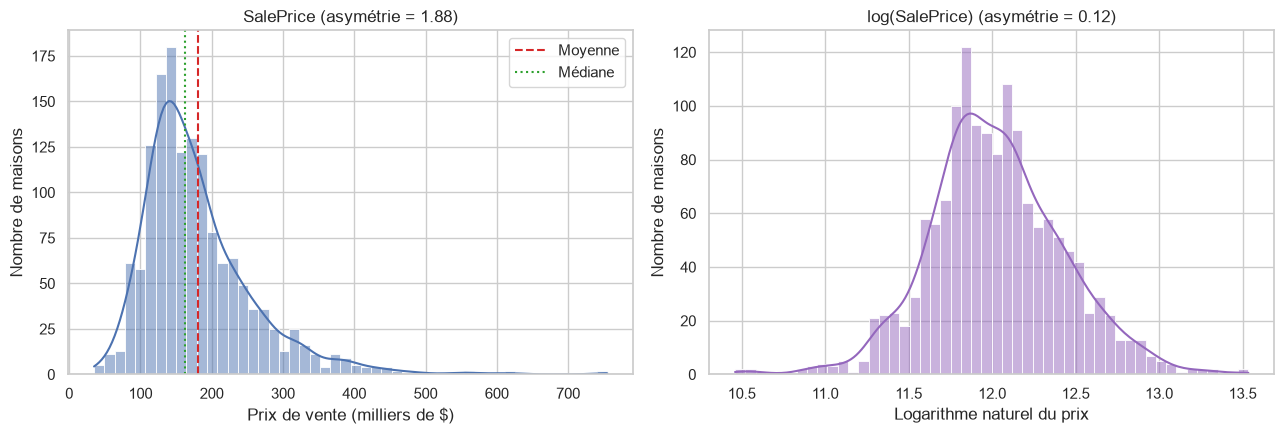

In [11]:
log_price = np.log(price)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(price / 1000, bins=50, kde=True, ax=axes[0])
axes[0].axvline(price.mean() / 1000, color="tab:red", linestyle="--", label="Moyenne")
axes[0].axvline(price.median() / 1000, color="tab:green", linestyle=":", label="Médiane")
axes[0].set_title(f"SalePrice (asymétrie = {price.skew():.2f})")
axes[0].set_xlabel("Prix de vente (milliers de $)")
axes[0].set_ylabel("Nombre de maisons")
axes[0].legend()

sns.histplot(log_price, bins=50, kde=True, ax=axes[1], color="tab:purple")
axes[1].set_title(f"log(SalePrice) (asymétrie = {log_price.skew():.2f})")
axes[1].set_xlabel("Logarithme naturel du prix")
axes[1].set_ylabel("Nombre de maisons")

plt.tight_layout()
plt.show()

**Question.** La distribution des prix est-elle symétrique, et la transformation logarithmique utilisée par la métrique Kaggle la rend-elle plus régulière?

**Observation.** À gauche, la plupart des maisons se vendent entre 100 000 \$ et 250 000 \$, avec une longue queue vers la droite jusqu'à 755 000 \$; la moyenne (ligne rouge) est à droite de la médiane (ligne verte). À droite, la distribution de `log(SalePrice)` est presque symétrique : l'asymétrie passe de 1,88 à 0,12.

**Interprétation.** Les prix varient plutôt de façon proportionnelle : un écart de 50 000 \$ est important pour une maison de 100 000 \$, mais modeste pour une maison de 600 000 \$. Le logarithme ramène ces écarts relatifs sur une échelle comparable. C'est aussi l'échelle de la métrique officielle, la RMSE des logarithmes présentée à l'étape 2.

**Conséquence.** Nous prévoyons d'entraîner les modèles sur `log(SalePrice)`, puis de reconvertir les prédictions en dollars avec l'exponentielle. Avec cette transformation, l'erreur minimisée pendant l'apprentissage correspond à la mesure de Kaggle.

### Asymétrie des caractéristiques numériques

In [12]:
skewness = pd.DataFrame({
    "Asymétrie": train[numeric_features].skew(),
    "Part de zéros (%)": (train[numeric_features].eq(0).mean() * 100),
}).round(2).sort_values("Asymétrie", ascending=False)

print(f"{skewness['Asymétrie'].gt(1).sum()} variables numériques sur "
      f"{len(numeric_features)} ont une asymétrie supérieure à 1.")
display(skewness.head(12))

18 variables numériques sur 35 ont une asymétrie supérieure à 1.


,Asymétrie,Part de zéros (%)
MiscVal,24.48,96.44
PoolArea,14.83,99.52
LotArea,12.21,0.00
3SsnPorch,10.30,98.36
LowQualFinSF,9.01,98.22
KitchenAbvGr,4.49,0.07
BsmtFinSF2,4.26,88.56
ScreenPorch,4.12,92.05
BsmtHalfBath,4.10,94.38
EnclosedPorch,3.09,85.75


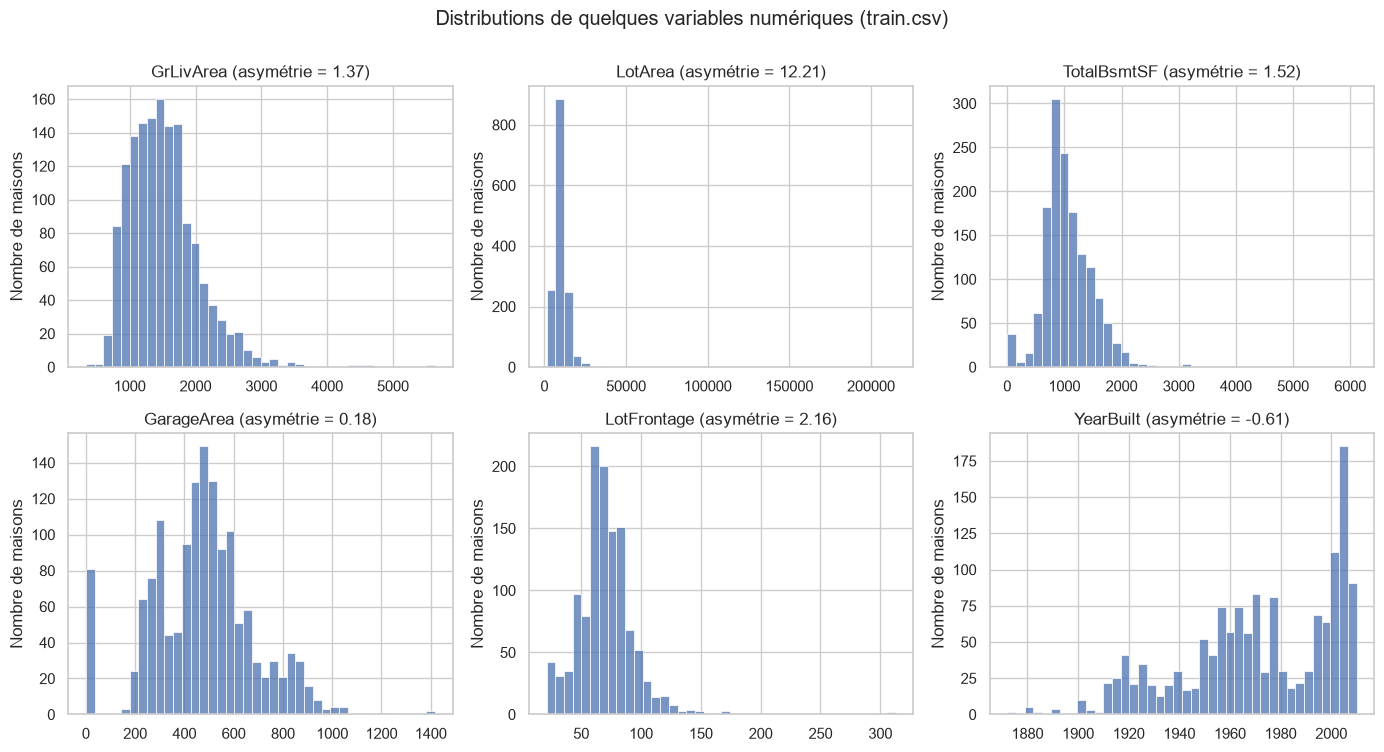

In [13]:
distribution_columns = [
    "GrLivArea", "LotArea", "TotalBsmtSF", "GarageArea", "LotFrontage", "YearBuilt",
]
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, column in zip(axes.flat, distribution_columns):
    sns.histplot(train[column].dropna(), bins=40, ax=ax)
    ax.set_title(f"{column} (asymétrie = {train[column].skew():.2f})")
    ax.set_xlabel("")
    ax.set_ylabel("Nombre de maisons")
fig.suptitle("Distributions de quelques variables numériques (train.csv)", y=1.0)
plt.tight_layout()
plt.show()

**Question.** Les caractéristiques numériques ont-elles, elles aussi, des distributions asymétriques ou des valeurs extrêmes?

**Observation.** Le tableau montre que 18 variables numériques sur 35 ont une asymétrie supérieure à 1. Les plus asymétriques (`MiscVal`, `PoolArea`, `3SsnPorch`, `LowQualFinSF`) valent 0 pour plus de 96 % des maisons : leur asymétrie vient surtout de cette masse de zéros. Dans la figure, `LotArea` (asymétrie de 12,21) est concentrée sous 20 000 pi², avec quelques terrains dépassant 100 000 pi². `GrLivArea`, `TotalBsmtSF` et `LotFrontage` ont une queue à droite; `GarageArea` présente un pic à 0 correspondant aux maisons sans garage. `YearBuilt` est asymétrique vers la gauche : les constructions récentes, autour de 2000-2007, sont nombreuses.

**Interprétation.** Deux situations différentes produisent une forte asymétrie : des grandeurs positives étirées vers la droite (surfaces) et des variables surtout nulles (piscine, galeries, équipements divers). Pour ces dernières, l'information utile est souvent la présence ou l'absence de l'équipement plutôt que sa surface exacte.

**Conséquence.** À l'étape 4, nous pourrons appliquer une transformation logarithmique (`log1p`, qui accepte les zéros) aux surfaces très asymétriques si le modèle choisi y est sensible, par exemple une régression linéaire. Pour les variables presque toujours nulles, un indicateur de présence pourrait remplacer ou compléter la surface. Les modèles à base d'arbres sont moins sensibles à ces distributions.

### Valeurs atypiques

In [15]:
q1, q3 = price.quantile([0.25, 0.75])
upper_limit = q3 + 1.5 * (q3 - q1)
log_q1, log_q3 = log_price.quantile([0.25, 0.75])
log_spread = log_q3 - log_q1
log_outside = log_price.lt(log_q1 - 1.5 * log_spread) | log_price.gt(log_q3 + 1.5 * log_spread)

print(f"Seuil haut (Q3 + 1,5 × (Q3 − Q1)) pour SalePrice : {format_dollars(upper_limit)}")
print(f"Maisons au-dessus de ce seuil : {price.gt(upper_limit).sum()}")
print(f"Maisons hors des bornes sur log(SalePrice) : {log_outside.sum()}")

large_houses = train.loc[
    train["GrLivArea"].gt(4000),
    ["Id", "GrLivArea", "SalePrice", "OverallQual", "Neighborhood", "SaleCondition"],
]
display(large_houses.sort_values("GrLivArea"))
print(f"Maisons de test avec GrLivArea > 4000 : {test['GrLivArea'].gt(4000).sum()}")

Seuil haut (Q3 + 1,5 × (Q3 − Q1)) pour SalePrice : 340 038 $
Maisons au-dessus de ce seuil : 61
Maisons hors des bornes sur log(SalePrice) : 28


,Id,GrLivArea,SalePrice,OverallQual,Neighborhood,SaleCondition
691,692,4316,755000,10,NoRidge,Normal
1182,1183,4476,745000,10,NoRidge,Abnorml
523,524,4676,184750,10,Edwards,Partial
1298,1299,5642,160000,10,Edwards,Partial


Maisons de test avec GrLivArea > 4000 : 1


Pour repérer les prix atypiques, nous utilisons la règle de la boîte à moustaches. L'écart interquartile est Q3 − Q1, où Q1 et Q3 sont les 1er et 3e quartiles. Un prix est jugé atypique s'il est inférieur à Q1 − 1,5 × (Q3 − Q1) ou supérieur à Q3 + 1,5 × (Q3 − Q1). Selon cette règle, **61 prix dépassent 340 038 $**. Sur l'échelle logarithmique, il ne reste que 28 prix hors des bornes. La majorité des « valeurs atypiques » en dollars sont donc des maisons chères qui suivent la tendance générale des prix, pas des erreurs.

Le tableau des quatre maisons de plus de 4 000 pi² est plus révélateur. Deux maisons de `NoRidge` (Id 692 et 1183) ont les prix les plus élevés des données, ce qui est cohérent avec leur taille. En revanche, les maisons 524 et 1299, situées dans `Edwards`, ont une qualité maximale et une très grande surface, mais des prix inférieurs à 185 000 $. Ces deux ventes sont de type `Partial`, c'est-à-dire des maisons neuves vendues avant la fin de leur construction. La section 7.1 les situe dans le nuage de points.

Une maison de `test.csv` dépasse aussi 4 000 pi². Nous en tiendrons compte avant de décider de retirer des maisons atypiques de l'entraînement.

## 6. Corrélations

Nous mesurons l'association entre chaque caractéristique numérique et le prix avec deux coefficients :

- le **coefficient de Spearman**, calculé sur les rangs, mesure une relation monotone, même non linéaire, et est peu sensible aux valeurs extrêmes;
- le **coefficient de Pearson**, qui mesure une relation linéaire. Nous le calculons sur `SalePrice` et sur `log(SalePrice)`, l'échelle retenue pour la modélisation.

Les valeurs manquantes sont ignorées paire par paire. Les variables catégorielles, absentes de ce calcul, sont étudiées graphiquement à la section 7.

In [16]:
correlations = pd.DataFrame({
    "Spearman (SalePrice)": train[numeric_features].corrwith(price, method="spearman"),
    "Pearson (log SalePrice)": train[numeric_features].corrwith(log_price),
    "Pearson (SalePrice)": train[numeric_features].corrwith(price),
}).round(3).sort_values("Spearman (SalePrice)", ascending=False)

display(correlations.head(12))
display(correlations.tail(4))

,Spearman (SalePrice),Pearson (log SalePrice),Pearson (SalePrice)
OverallQual,0.810,0.817,0.791
GrLivArea,0.731,0.701,0.709
GarageCars,0.691,0.681,0.640
YearBuilt,0.653,0.587,0.523
GarageArea,0.649,0.651,0.623
FullBath,0.636,0.595,0.561
TotalBsmtSF,0.603,0.612,0.614
GarageYrBlt,0.594,0.541,0.486
1stFlrSF,0.575,0.597,0.606
YearRemodAdd,0.571,0.566,0.507


,Spearman (SalePrice),Pearson (log SalePrice),Pearson (SalePrice)
LowQualFinSF,-0.068,-0.038,-0.026
OverallCond,-0.129,-0.037,-0.078
KitchenAbvGr,-0.165,-0.148,-0.136
EnclosedPorch,-0.218,-0.149,-0.129


La qualité globale `OverallQual` est la variable la plus liée au prix (Spearman de 0,81), suivie de la surface habitable `GrLivArea` (0,73), de la taille du garage (`GarageCars`, `GarageArea`), de l'année de construction et de la surface du sous-sol. Pour `YearBuilt` et `GarageYrBlt`, Pearson est plus élevé sur le logarithme du prix (0,587 contre 0,523 pour `YearBuilt`) : la relation est plus linéaire sur cette échelle. Les corrélations négatives sont faibles; aucune ne dépasse 0,22 en valeur absolue. `OverallCond` est presque indépendante du prix (-0,13), contrairement à `OverallQual`.

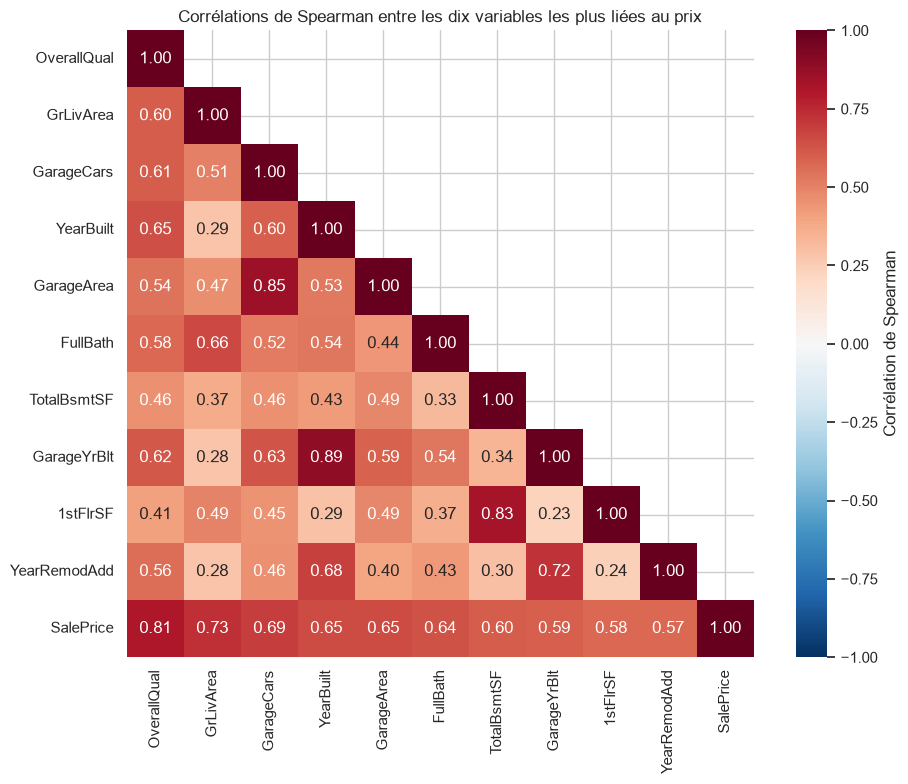

In [17]:
top_features = correlations.head(10).index.tolist()
spearman_matrix = train[top_features + ["SalePrice"]].corr(method="spearman")
mask = np.triu(np.ones_like(spearman_matrix, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(spearman_matrix, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, square=True, cbar_kws={"label": "Corrélation de Spearman"},
            ax=ax)
ax.set_title("Corrélations de Spearman entre les dix variables les plus liées au prix")
plt.tight_layout()
plt.show()

**Question.** Les variables les plus liées au prix apportent-elles des informations distinctes, ou certaines se répètent-elles?

**Observation.** La dernière ligne reprend les corrélations avec le prix, de 0,81 à 0,57. Dans le triangle, certaines paires de caractéristiques sont très fortement corrélées : `YearBuilt` et `GarageYrBlt` (0,89), `GarageCars` et `GarageArea` (0,85), `TotalBsmtSF` et `1stFlrSF` (0,83). `OverallQual` est modérément corrélée à presque toutes les autres variables (0,41 à 0,65).

**Interprétation.** Ces paires décrivent presque la même chose : un garage est souvent construit en même temps que la maison, sa capacité en voitures dépend de sa superficie, et le rez-de-chaussée recouvre généralement le sous-sol. La qualité globale semble résumer plusieurs aspects de la maison, ce qui contribue à sa forte association avec le prix.

**Conséquence.** Les variables redondantes (multicolinéarité) rendent instables les coefficients d'une régression linéaire non régularisée. Nous pourrons conserver une seule variable par paire, créer des variables combinées (par exemple une surface totale) ou utiliser une régularisation (Ridge, Lasso). Le tableau suivant liste toutes les paires de caractéristiques numériques dont la corrélation de Spearman atteint 0,8.

In [18]:
feature_matrix = train[numeric_features].corr(method="spearman").abs()
upper = feature_matrix.where(np.triu(np.ones(feature_matrix.shape, dtype=bool), k=1))
strong_pairs = (
    upper.stack()
    .loc[lambda values: values >= 0.8]
    .sort_values(ascending=False)
    .round(3)
    .rename("|Spearman|")
    .rename_axis(["Variable 1", "Variable 2"])
    .reset_index()
)
display(strong_pairs)

,Variable 1,Variable 2,|Spearman|
0,YearBuilt,GarageYrBlt,0.891
1,GarageArea,GarageCars,0.853
2,TotalBsmtSF,1stFlrSF,0.829
3,GrLivArea,TotRmsAbvGrd,0.828


Quatre paires atteignent ce seuil. La quatrième, `GrLivArea` et `TotRmsAbvGrd` (0,83), était hors de la carte précédente, car `TotRmsAbvGrd` ne fait pas partie des dix variables les plus liées au prix. Une grande maison compte naturellement plus de pièces. Ces quatre paires seront nos premières candidates pour la sélection ou la combinaison de caractéristiques.

## 7. Visualisations pertinents

Cette section approfondit les variables les plus importantes pour la suite : `GrLivArea` et `OverallQual`, les plus corrélées au prix, ainsi que les catégories `Neighborhood`, `BldgType` et `MSSubClass`, absentes de l'analyse des corrélations. Nous terminons avec l'année de construction et les conditions de vente.

### 7.1 Superficie habitable (`GrLivArea`)

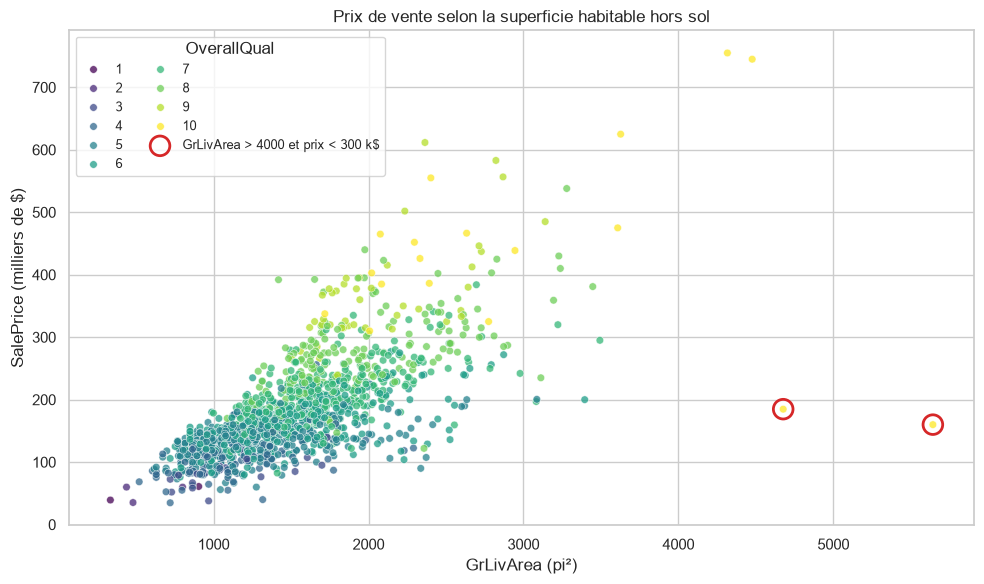

Spearman GrLivArea–SalePrice : 0.731
Pearson sans les 2 maisons encerclées : 0.735 (avec : 0.709)


In [19]:
unusual = train["GrLivArea"].gt(4000) & price.lt(300_000)

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=train, x="GrLivArea", y=price / 1000, hue="OverallQual",
                palette="viridis", legend="full", alpha=0.75, s=30, ax=ax)
ax.scatter(train.loc[unusual, "GrLivArea"], price[unusual] / 1000, s=200,
           facecolors="none", edgecolors="tab:red", linewidths=2,
           label="GrLivArea > 4000 et prix < 300 k$")
ax.set_title("Prix de vente selon la superficie habitable hors sol")
ax.set_xlabel("GrLivArea (pi²)")
ax.set_ylabel("SalePrice (milliers de $)")
ax.legend(title="OverallQual", ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

print(f"Spearman GrLivArea–SalePrice : {train['GrLivArea'].corr(price, method='spearman'):.3f}")
print(f"Pearson sans les {unusual.sum()} maisons encerclées : "
      f"{train.loc[~unusual, 'GrLivArea'].corr(price[~unusual]):.3f} "
      f"(avec : {train['GrLivArea'].corr(price):.3f})")

**Question.** Le prix augmente-t-il avec la superficie habitable, et certaines maisons s'écartent-elles de cette tendance?

**Observation.** Le nuage de points montre une relation croissante : les prix augmentent avec la superficie, et la couleur indique que les grandes maisons ont aussi souvent une qualité élevée. La dispersion des prix augmente avec la surface : en dessous de 1 000 pi², les prix sont regroupés, alors qu'ils varient de 200 000 \$ à plus de 600 000 \$ autour de 2 500 pi². Les deux maisons encerclées, de plus de 4 500 pi² et de qualité 10, se vendent moins de 190 000 \$, loin de la tendance. Sans elles, la corrélation de Pearson passe de 0,709 à 0,735.

**Interprétation.** La surface est un bon indicateur du prix, mais pas le seul : à surface égale, la qualité fait varier le prix. La dispersion croissante est cohérente avec des variations proportionnelles aux prix, que le logarithme stabilise. Les deux maisons encerclées sont probablement des ventes particulières (`Partial`, dans `Edwards`) plutôt que des erreurs de mesure. Leur prix ne reflète peut-être pas la valeur marchande d'une maison terminée.

**Conséquence.** Ces deux maisons pourraient fortement influencer un modèle linéaire. La documentation du jeu de données d'Ames recommande de retirer les maisons de plus de 4 000 pi² de l'entraînement. Cependant, la maison de `test.csv` qui dépasse 4 000 pi² est également une vente `Partial` de qualité 10 dans `Edwards` (Id 2550). À l'étape 4, nous comparerons donc par validation croisée un entraînement avec et sans ces deux maisons, plutôt que de les retirer sans vérification.

### 7.2 Qualité globale (`OverallQual`)

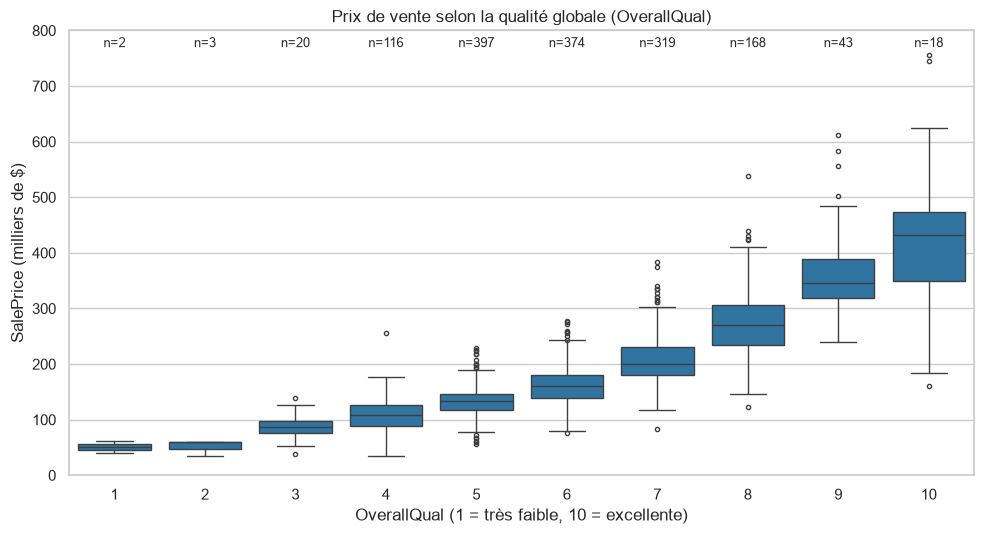

OverallQual,1,2,3,4,5,6,7,8,9,10
Prix médian,50 150 $,60 000 $,86 250 $,108 000 $,133 000 $,160 000 $,200 141 $,269 750 $,345 000 $,432 390 $


In [20]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=train, x="OverallQual", y=price / 1000, color="tab:blue",
            fliersize=3, ax=ax)
quality_counts = train["OverallQual"].value_counts().sort_index()
for position, count in enumerate(quality_counts):
    ax.text(position, 770, f"n={count}", ha="center", fontsize=9)
ax.set_ylim(0, 800)
ax.set_title("Prix de vente selon la qualité globale (OverallQual)")
ax.set_xlabel("OverallQual (1 = très faible, 10 = excellente)")
ax.set_ylabel("SalePrice (milliers de $)")
plt.tight_layout()
plt.show()

display(train.groupby("OverallQual")["SalePrice"].median().map(format_dollars)
        .rename("Prix médian").to_frame().T)

**Question.** Comment le prix évolue-t-il selon la qualité globale de la maison?

**Observation.** Le prix médian augmente à chaque niveau de qualité, de 50 150 \$ au niveau 1 à 432 390 \$ au niveau 10. Les augmentations s'accélèrent : environ 25 000 \$ entre les niveaux 4 et 5, mais près de 90 000 \$ entre les niveaux 9 et 10. La hauteur des boîtes augmente aussi avec la qualité. Les niveaux 1 à 3 ne comptent que 25 maisons au total.

**Interprétation.** La relation est monotone, mais pas linéaire en dollars : elle ressemble plutôt à une croissance exponentielle, donc à une relation proche d'une droite sur l'échelle logarithmique. Les estimations pour les niveaux extrêmes reposent sur peu de maisons et sont donc moins fiables.

**Conséquence.** `OverallQual` devrait être une variable centrale du modèle. Nous la conserverons comme variable numérique ordonnée. Le passage au logarithme du prix devrait rendre sa relation avec la cible plus linéaire.

### 7.3 Quartier (`Neighborhood`)

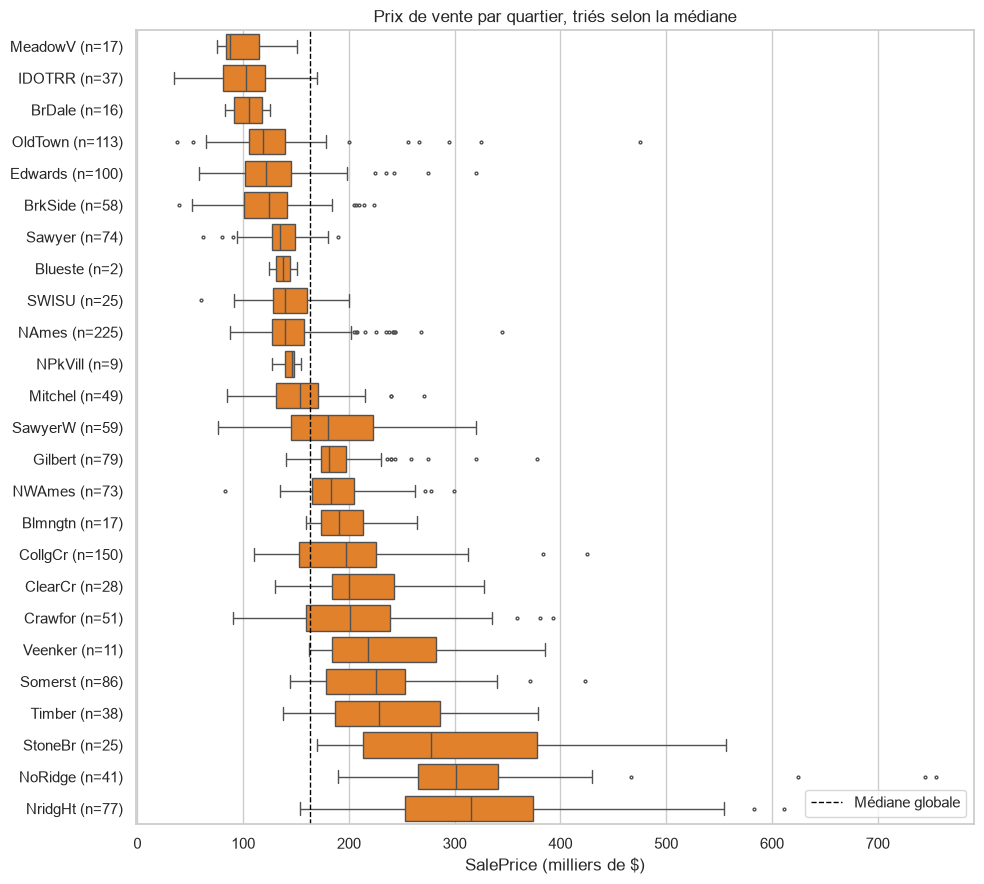

Rapport entre la médiane la plus élevée et la plus faible : 3.6
Quartiers avec moins de 20 ventes : 6


In [21]:
neighborhood_stats = (
    train.groupby("Neighborhood")["SalePrice"].agg(["count", "median"])
    .sort_values("median")
)
order = neighborhood_stats.index.tolist()

fig, ax = plt.subplots(figsize=(10, 9))
sns.boxplot(data=train, y="Neighborhood", x=price / 1000, order=order,
            color="tab:orange", fliersize=2, ax=ax)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{name} (n={neighborhood_stats.loc[name, 'count']})" for name in order])
ax.axvline(price.median() / 1000, color="black", linestyle="--", linewidth=1,
           label="Médiane globale")
ax.set_title("Prix de vente par quartier, triés selon la médiane")
ax.set_xlabel("SalePrice (milliers de $)")
ax.set_ylabel("")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

ratio = neighborhood_stats["median"].max() / neighborhood_stats["median"].min()
print(f"Rapport entre la médiane la plus élevée et la plus faible : {ratio:.1f}")
print(f"Quartiers avec moins de 20 ventes : {neighborhood_stats['count'].lt(20).sum()}")

**Question.** Le quartier est-il associé à des différences de prix importantes?

**Observation.** Les prix médians vont de 88 000 \$ à `MeadowV` jusqu'à 315 000 \$ à `NridgHt`, soit un rapport de 3,6. Trois quartiers (`StoneBr`, `NoRidge` et `NridgHt`) se démarquent nettement au-dessus de la médiane globale, tandis que plusieurs quartiers plus anciens (`IDOTRR`, `OldTown`, `Edwards`, `BrkSide`) se situent bien en dessous. La dispersion varie beaucoup selon le quartier : elle est faible à `NPkVill` et forte à `StoneBr` et `NridgHt`. Six quartiers comptent moins de 20 ventes, dont `Blueste` avec seulement 2 maisons.

**Interprétation.** La localisation est fortement associée au prix. Elle reflète probablement aussi d'autres caractéristiques, comme l'âge et la taille des maisons, plutôt qu'un effet du quartier seul. Pour les petits quartiers, l'estimation d'un prix typique est incertaine.

**Conséquence.** `Neighborhood` devra être conservée et encodée sans ordre artificiel, par exemple en *one-hot*, ce qui ajoutera 25 colonnes. Les quartiers à faible effectif pourraient être regroupés avec des quartiers semblables. Un encodage par le prix moyen du quartier (*target encoding*) devrait être calculé à l'intérieur de chaque pli de validation, pour éviter que le modèle voie les prix qu'il doit prédire.

### 7.4 Type de bâtiment (`BldgType`)

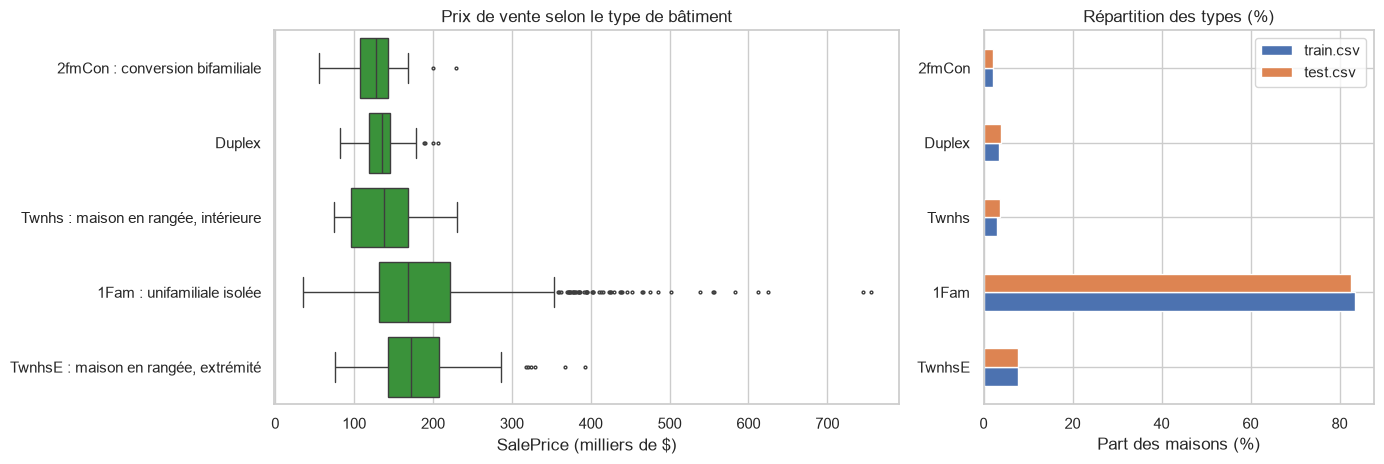

,train.csv,test.csv,Prix médian (train)
BldgType,,,
2fmCon,31,31,127 500 $
Duplex,52,57,135 980 $
Twnhs,43,53,137 500 $
1Fam,1220,1205,167 900 $
TwnhsE,114,113,172 200 $


In [22]:
bldg_labels = {
    "1Fam": "1Fam : unifamiliale isolée",
    "TwnhsE": "TwnhsE : maison en rangée, extrémité",
    "Twnhs": "Twnhs : maison en rangée, intérieure",
    "Duplex": "Duplex",
    "2fmCon": "2fmCon : conversion bifamiliale",
}
bldg_order = (train.groupby("BldgType")["SalePrice"].median().sort_values().index.tolist())
bldg_counts = pd.DataFrame({
    "train.csv": train["BldgType"].value_counts(),
    "test.csv": test["BldgType"].value_counts(),
}).loc[bldg_order]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
sns.boxplot(data=train, y="BldgType", x=price / 1000, order=bldg_order,
            color="tab:green", fliersize=2, ax=axes[0])
axes[0].set_yticks(range(len(bldg_order)))
axes[0].set_yticklabels([bldg_labels[name] for name in bldg_order])
axes[0].set_title("Prix de vente selon le type de bâtiment")
axes[0].set_xlabel("SalePrice (milliers de $)")
axes[0].set_ylabel("")

# barh trace de bas en haut : inverser l'ordre pour aligner les deux panneaux.
(bldg_counts / bldg_counts.sum() * 100).iloc[::-1].plot.barh(ax=axes[1])
axes[1].set_title("Répartition des types (%)")
axes[1].set_xlabel("Part des maisons (%)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

display(bldg_counts.assign(**{
    "Prix médian (train)": train.groupby("BldgType")["SalePrice"].median()
    .loc[bldg_order].map(format_dollars)
}))

**Question.** Le type de bâtiment influence-t-il le prix, et sa répartition est-elle la même dans les deux fichiers?

**Observation.** Les maisons unifamiliales isolées (`1Fam`) représentent environ 84 % des ventes de `train.csv` et 83 % de `test.csv`. Les écarts de prix médian entre types restent modestes : de 127 500 \$ pour les conversions bifamiliales (`2fmCon`) à 172 200 \$ pour les maisons en rangée situées en extrémité (`TwnhsE`). Les maisons `1Fam` ont la plus grande dispersion et contiennent presque toutes les maisons chères. La répartition des types est très semblable entre les deux fichiers.

**Interprétation.** Le type de bâtiment distingue surtout les logements multifamiliaux et les maisons en rangée intérieures, moins chers, des autres maisons. Comme la plupart des maisons sont `1Fam`, cette variable explique seulement une petite partie des écarts de prix; la surface, la qualité et le quartier semblent plus déterminants.

**Conséquence.** `BldgType` pourra être encodée en *one-hot* sans difficulté particulière, car ses cinq modalités sont présentes dans les deux fichiers. Nous devrons cependant vérifier sa redondance avec `MSSubClass` (section suivante).

### 7.5 Type de logement (`MSSubClass`)

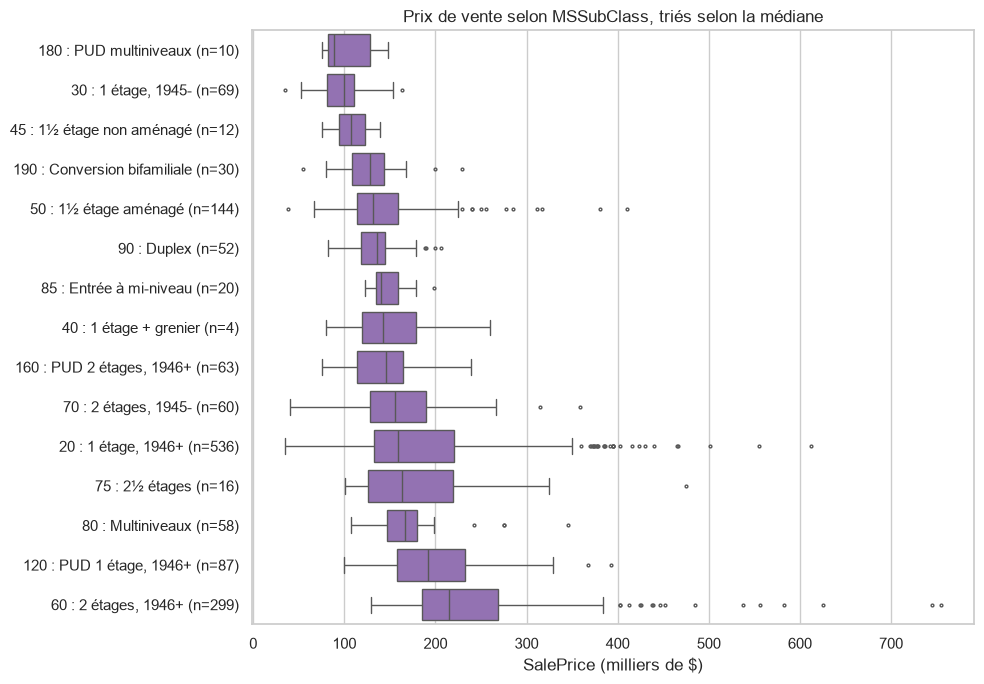

MSSubClass,20,30,40,45,50,60,70,75,80,85,90,120,150,160,180,190
train.csv,536,69,4,12,144,299,60,16,58,20,52,87,0,63,10,30
test.csv,543,70,2,6,143,276,68,7,60,28,57,95,1,65,7,31


Correspondance MSSubClass → BldgType (nombre de maisons de train) :


BldgType,1Fam,2fmCon,Duplex,Twnhs,TwnhsE
MSSubClass,,,,,
20,535,1,0,0,0
30,69,0,0,0,0
40,4,0,0,0,0
45,12,0,0,0,0
50,144,0,0,0,0
60,299,0,0,0,0
70,60,0,0,0,0
75,16,0,0,0,0
80,58,0,0,0,0


In [23]:
subclass_labels = {
    20: "1 étage, 1946+", 30: "1 étage, 1945-", 40: "1 étage + grenier",
    45: "1½ étage non aménagé", 50: "1½ étage aménagé", 60: "2 étages, 1946+",
    70: "2 étages, 1945-", 75: "2½ étages", 80: "Multiniveaux", 85: "Entrée à mi-niveau",
    90: "Duplex", 120: "PUD 1 étage, 1946+", 150: "PUD 1½ étage",
    160: "PUD 2 étages, 1946+", 180: "PUD multiniveaux", 190: "Conversion bifamiliale",
}
subclass_stats = (
    train.groupby("MSSubClass")["SalePrice"].agg(["count", "median"]).sort_values("median")
)
subclass_order = subclass_stats.index.tolist()

fig, ax = plt.subplots(figsize=(10, 7))
sns.boxplot(data=train, y=train["MSSubClass"].astype(str), x=price / 1000,
            order=[str(code) for code in subclass_order], color="tab:purple",
            fliersize=2, ax=ax)
ax.set_yticks(range(len(subclass_order)))
ax.set_yticklabels([
    f"{code} : {subclass_labels[code]} (n={subclass_stats.loc[code, 'count']})"
    for code in subclass_order
])
ax.set_title("Prix de vente selon MSSubClass, triés selon la médiane")
ax.set_xlabel("SalePrice (milliers de $)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

subclass_counts = pd.DataFrame({
    "train.csv": train["MSSubClass"].value_counts(),
    "test.csv": test["MSSubClass"].value_counts(),
}).fillna(0).astype(int).sort_index()
display(subclass_counts.T)
print("Correspondance MSSubClass → BldgType (nombre de maisons de train) :")
display(pd.crosstab(train["MSSubClass"], train["BldgType"]))

**Question.** Les codes de `MSSubClass` sont-ils associés au prix, et cette variable apporte-t-elle une information différente de `BldgType`?

**Observation.** Les prix médians vont de 88 500 \$ pour le code 180 (PUD multiniveaux) à 215 200 \$ pour le code 60 (2 étages construits depuis 1946). L'ordre des prix ne suit pas l'ordre numérique des codes : par exemple, le code 120 a un prix médian plus élevé que tous les codes de 20 à 90. Le code 150 est absent de `train.csv`, mais apparaît une fois dans `test.csv`; les codes 40, 45, 75 et 180 comptent moins de 20 maisons. Le tableau croisé montre que les codes 90 et 190 correspondent presque exactement aux types `Duplex` et `2fmCon`, et que les codes 120, 160 et 180 (PUD) regroupent toutes les maisons en rangée (`Twnhs` et `TwnhsE`).

**Interprétation.** `MSSubClass` combine plusieurs informations : le type de bâtiment, le nombre d'étages et une période de construction (avant ou après 1946). Elle est donc en partie redondante avec `BldgType`, `HouseStyle` et `YearBuilt`. Le code numérique n'a aucune signification quantitative.

**Conséquence.** `MSSubClass` doit être convertie en catégorie avant l'encodage. L'encodeur devra accepter une catégorie inconnue pour le code 150 de `test.csv`, par exemple avec `OneHotEncoder(handle_unknown="ignore")`. Les codes rares pourraient être regroupés.

### 7.6 Année de construction et conditions de vente

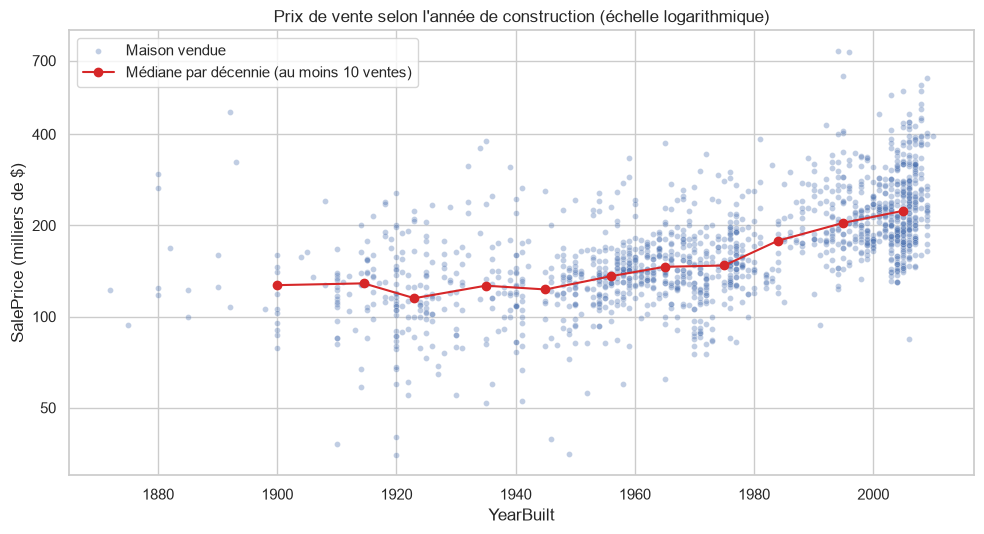

SaleCondition,AdjLand,Abnorml,Family,Alloca,Normal,Partial
Nombre,4,101,20,12,1198,125
Prix médian,104 000 $,130 000 $,140 500 $,148 145 $,160 000 $,244 600 $


YearBuilt,1900,1910,1920,1930,1940,1950,1960,1970,1980,1990,2000
Prix médian,127 000 $,128 750 $,115 000 $,126 500 $,122 900 $,136 000 $,146 000 $,147 500 $,178 000 $,204 000 $,223 500 $


YearBuilt médiane, ventes Partial : 2006 | autres ventes : 1970


In [24]:
decade = (train["YearBuilt"] // 10) * 10
# Conserver seulement les décennies d'au moins 10 ventes pour la courbe des médianes.
decade_counts = decade.value_counts()
reliable = decade.isin(decade_counts[decade_counts >= 10].index)
decade_median = price[reliable].groupby(decade[reliable]).median()
decade_position = train.loc[reliable, "YearBuilt"].groupby(decade[reliable]).median()

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.scatterplot(x=train["YearBuilt"], y=price / 1000, alpha=0.35, s=18, ax=ax,
                label="Maison vendue")
ax.plot(decade_position, decade_median / 1000, color="tab:red", marker="o",
        label="Médiane par décennie (au moins 10 ventes)")
ax.set_yscale("log")
ax.set_yticks([50, 100, 200, 400, 700])
ax.set_yticklabels(["50", "100", "200", "400", "700"])
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_title("Prix de vente selon l'année de construction (échelle logarithmique)")
ax.set_xlabel("YearBuilt")
ax.set_ylabel("SalePrice (milliers de $)")
ax.legend()
plt.tight_layout()
plt.show()

display(train.groupby("SaleCondition")["SalePrice"].agg(["count", "median"])
        .sort_values("median")
        .assign(median=lambda frame: frame["median"].map(format_dollars))
        .rename(columns={"count": "Nombre", "median": "Prix médian"}).T)
display(decade_median.map(format_dollars).rename("Prix médian").to_frame().T)
print("YearBuilt médiane, ventes Partial :",
      int(train.loc[train["SaleCondition"].eq("Partial"), "YearBuilt"].median()),
      "| autres ventes :",
      int(train.loc[train["SaleCondition"].ne("Partial"), "YearBuilt"].median()))

**Question.** Les maisons récentes se vendent-elles plus cher, et les conditions de vente modifient-elles le prix?

**Observation.** Sur l'échelle logarithmique, le prix médian reste à peu près stable, autour de 115 000 \$ à 150 000 \$, pour les maisons construites avant 1980. Il augmente ensuite régulièrement : 178 000 \$ pour les années 1980, 204 000 \$ pour les années 1990 et 223 500 \$ pour les années 2000. À chaque époque, les prix restent très dispersés. Les ventes `Partial` (125 maisons) ont un prix médian de 244 600 \$, nettement supérieur aux ventes `Normal` (160 000 \$). Elles concernent des maisons construites en 2006 en médiane, contre 1970 pour les autres ventes. Les ventes `Abnorml` (ventes forcées, saisies) ont un prix médian plus faible (130 000 \$).

**Interprétation.** La relation entre l'année de construction et le prix n'est pas linéaire : l'âge semble surtout distinguer les constructions récentes. Les maisons plus récentes sont aussi souvent plus grandes et de meilleure qualité, si bien que l'effet de l'âge seul ne peut pas être isolé ici. Les ventes `Partial` sont surtout des maisons neuves; leur prix élevé reflète probablement ces caractéristiques plutôt que la condition de vente elle-même.

**Conséquence.** Nous pourrons créer des variables plus interprétables, comme l'âge au moment de la vente (`YrSold - YearBuilt`) et le temps écoulé depuis la rénovation. `SaleCondition` sera conservée comme catégorie, car les ventes `Abnorml` et `Partial` peuvent expliquer des écarts que les caractéristiques de la maison n'expliquent pas.

## 8. Synthèse et limites

### Principaux constats

| Constat | Élément de preuve | Piste pour le prétraitement (étape 4) |
|---|---|---|
| Prix asymétrique vers la droite | Asymétrie de 1,88, ramenée à 0,12 par le logarithme | Modéliser `log(SalePrice)`, conforme à la métrique Kaggle |
| La plupart des `NA` indiquent une absence d'équipement | 14 variables; proportions semblables dans train et test | Remplacer ces `NA` par une catégorie « Aucun » (ou 0 pour les surfaces) |
| Quelques vraies valeurs inconnues | `LotFrontage` (17,7 %), quelques valeurs dans test pour 15 variables complètes dans train | Imputer dans un pipeline ajusté sur l'entraînement seulement |
| Incohérences ponctuelles | `GarageYrBlt` = 2207, équipements partiellement renseignés dans test | Corriger les erreurs évidentes; vérifier la cohérence entre variables liées |
| Codes différents du dictionnaire | `BldgType`, `Exterior2nd`, `MSZoning`, `Neighborhood` | Harmoniser `Exterior1st` et `Exterior2nd` avant toute combinaison |
| Variables numériques asymétriques ou surtout nulles | 18 variables sur 35 avec une asymétrie supérieure à 1 | Transformation `log1p` ou indicateurs de présence, selon le modèle |
| Deux ventes atypiques | Id 524 et 1299 : plus de 4 500 pi², moins de 185 000 $ | Comparer en validation croisée l'entraînement avec et sans ces maisons |
| Variables fortement associées au prix | `OverallQual` (0,81), `GrLivArea` (0,73), garage, année, sous-sol | Variables candidates prioritaires pour le modèle |
| Caractéristiques redondantes | Quatre paires avec une corrélation de Spearman ≥ 0,8 | Sélection, variables combinées (surface totale) ou régularisation |
| Catégories importantes, nombreuses ou rares | 25 quartiers; 7 variables quasi constantes; code 150 seulement dans test | *One-hot* tolérant aux catégories inconnues; regroupement des modalités rares |
| Années difficiles à interpréter directement | Prix stable avant 1980, puis croissant | Créer l'âge à la vente et le temps depuis la rénovation |

### Limites de l'analyse

- **Associations, pas causes.** Les relations observées ne démontrent pas qu'une caractéristique fait varier le prix. Par exemple, l'effet apparent de l'âge ou du quartier peut refléter la taille et la qualité des maisons.
- **Analyse principalement univariée et bivariée.** Nous avons examiné les variables une ou deux à la fois. Les interactions, par exemple entre la surface et le quartier, seront mieux évaluées par les modèles.
- **Petits effectifs.** Plusieurs catégories et niveaux de qualité comptent moins de 20 maisons; les différences observées pour ces groupes sont incertaines.
- **Corrélations limitées aux variables numériques.** Les coefficients de Spearman et de Pearson ne mesurent pas l'association avec les catégories, que nous avons étudiées graphiquement pour quelques variables seulement.
- **Portée des données.** Les ventes ont eu lieu à Ames entre 2006 et 2010, en partie pendant la crise immobilière de 2008. Nos constats ne s'appliquent pas directement à un autre marché ou à une autre période.
- **Utilisation de `test.csv`.** Nous l'avons consulté pour comparer les valeurs manquantes et les catégories, mais aucune statistique de ce fichier ne servira à ajuster le prétraitement.

## Références

- [Consignes originales MAP6014](../docs/travail-de-mi-session-v2.pdf), étape 3. Le document porte le titre « travail de mi-session »; nous l'utilisons comme consigne du présent travail de fin de session.
- [Kaggle — House Prices – Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data), données de la compétition.
- [Description locale des variables](../data/data_description.txt), pour la signification des codes et des valeurs `NA`.
- [Étape 2 — Présentation du problème](02_presentation_probleme.ipynb), pour le contexte, la métrique et le dictionnaire des variables.

**Convention de dépôt.** Les sorties de calcul sont effacées avant le commit, conformément au [guide de collaboration](../docs/collaboration.md). Exécuter les cellules dans l'ordre avec le kernel `.venv` pour afficher les tableaux et les figures. Les valeurs citées dans les commentaires proviennent de l'exécution complète de ce notebook sur les fichiers Kaggle locaux.